### Notebook 01: Preprocessing Citra Daun Pakcoy

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import dataclasses
import hashlib
import importlib
import json
import platform
import re
import sys
import time
from datetime import datetime
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import skimage
from PIL import Image
from skimage.color import rgb2lab
from skimage.filters import threshold_otsu

print("Python        :", platform.python_version())
print("NumPy         :", np.__version__)
print("pandas        :", pd.__version__)
print("OpenCV        :", cv2.__version__)
print("scikit-image  :", skimage.__version__)
print("matplotlib    :", matplotlib.__version__)

Python        : 3.10.6
NumPy         : 1.26.4
pandas        : 2.2.3
OpenCV        : 4.10.0
scikit-image  : 0.24.0
matplotlib    : 3.9.2


##### 1.2 Konfigurasi

In [2]:
def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "preprocessing.py").exists():
            return folder
        if (folder / "ml" / "src" / "preprocessing.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import preprocessing as pp

importlib.reload(pp)

SEED = 42
SEGMENTATION_CHANNEL = "b"  # "auto", "a", "b" or "chroma"
COMPONENT_RULE = "relative"  # "largest" or "relative"
MIN_COMPONENT_RATIO = 0.05
TUKEY_K = 3.0
CHANNEL_PREFERENCE = ("a", "b", "chroma")
DICE_AGREEMENT = 0.85
TIE_MARGIN = 0.05
GALLERY_SIZE = 8

RAW_DIR = ML_DIR / "data" / "raw"
MASK_DIR = ML_DIR / "data" / "interim" / "masks"
PROCESSED_DIR = ML_DIR / "data" / "processed"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
for folder in (MASK_DIR, PROCESSED_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RAW_FOLDERS = ("normal", "n_deficiency", "fe_deficiency", "primary")
EXPECTED_COUNTS = {"normal": 112, "n_deficiency": 92, "fe_deficiency": 176, "primary": 8}
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
CLASSES = ("normal", "n_deficiency", "fe_deficiency")
CHANNELS = pp.SEGMENTATION_CHANNELS

CLASS_LABEL_ID = {"normal": "Normal", "n_deficiency": "Defisiensi N", "fe_deficiency": "Defisiensi Fe"}
CLASS_COLORS = {"normal": "#009E73", "n_deficiency": "#E69F00", "fe_deficiency": "#CC79A7"}

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / name, bbox_inches="tight")


def to_rgb(bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def tint_overlay(bgr: np.ndarray, mask: np.ndarray) -> np.ndarray:
    base = to_rgb(bgr).astype(np.float32)
    tint = np.zeros_like(base)
    tint[..., 0] = 255.0
    return np.where(mask[..., None] > 0, 0.55 * base + 0.45 * tint, base).astype(np.uint8)


def dice(first: np.ndarray, second: np.ndarray) -> float:
    total = first.sum() + second.sum()
    return float(2.0 * np.logical_and(first, second).sum() / total) if total else 1.0


_resized_cache: dict = {}


def load_resized(folder: str, image_id: str) -> np.ndarray:
    key = (folder, image_id)
    if key not in _resized_cache:
        bgr = pp.read_image_bgr(RAW_DIR / folder / image_id)
        _resized_cache[key] = pp.resize_square(bgr, pp.PipelineConfig().resize)
    return _resized_cache[key]


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


#### 2. Inventaris Dataset

##### 2.1 Daftar berkas

In [3]:
GROUP_PATTERN = re.compile(r"^(?P<prefix>.+?)_(?:png|jpg|jpeg)\.rf\.[0-9a-fA-F]+$")

records = []
skipped = []
for folder_name in RAW_FOLDERS:
    folder = RAW_DIR / folder_name
    if not folder.is_dir():
        print(f"Folder tidak ada: {folder}")
        continue
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() not in IMAGE_SUFFIXES:
            skipped.append(str(path.relative_to(RAW_DIR)))
            continue
        is_primary = folder_name == "primary"
        label = "normal" if is_primary else folder_name
        match = GROUP_PATTERN.match(path.stem)
        prefix = match.group("prefix") if match else path.stem
        with Image.open(path) as image:
            width, height = image.size
        records.append(
            {
                "image_id": path.name,
                "folder": folder_name,
                "label": label,
                "origin": "primary" if is_primary else "roboflow",
                "prefix": prefix,
                "name_matches_pattern": bool(match) or is_primary,
                "source_group": "primary" if is_primary else f"{label}:{prefix}",
                "width": width,
                "height": height,
                "sha1": hashlib.sha1(path.read_bytes()).hexdigest(),
            }
        )

manifest = pd.DataFrame.from_records(records)
roboflow = manifest[manifest["origin"] == "roboflow"]

inventory = pd.DataFrame(
    {
        "ditemukan": manifest.groupby("folder").size().reindex(RAW_FOLDERS).fillna(0).astype(int),
        "diharapkan": pd.Series(EXPECTED_COUNTS),
    }
)
inventory["status"] = np.where(inventory["ditemukan"] == inventory["diharapkan"], "sesuai", "BERBEDA")
inventory.loc["total"] = [inventory["ditemukan"].sum(), inventory["diharapkan"].sum(), ""]
display(inventory)
print(f"Berkas bukan gambar diabaikan: {len(skipped)}")
print(f"Nama di luar pola Roboflow  : {int((~manifest['name_matches_pattern']).sum())}")

,ditemukan,diharapkan,status
normal,112,112,sesuai
n_deficiency,92,92,sesuai
fe_deficiency,176,176,sesuai
primary,8,8,sesuai
total,388,388,


Berkas bukan gambar diabaikan: 0
Nama di luar pola Roboflow  : 0


##### 2.2 Foto sumber unik

,berkas,foto_sumber_unik,berkas_per_foto_rata2,berkas_per_foto_median,berkas_per_foto_maks
label,,,,,
normal,112.0,72.0,1.56,1.0,6.0
n_deficiency,92.0,20.0,4.60,6.0,6.0
fe_deficiency,176.0,44.0,4.00,6.0,6.0
total,380.0,136.0,2.79,6.0,6.0


Awalan di lebih dari satu kelas: 13 dari 121
Berkas dengan isi persis sama  : 0
Konflik label (isi sama)       : 0


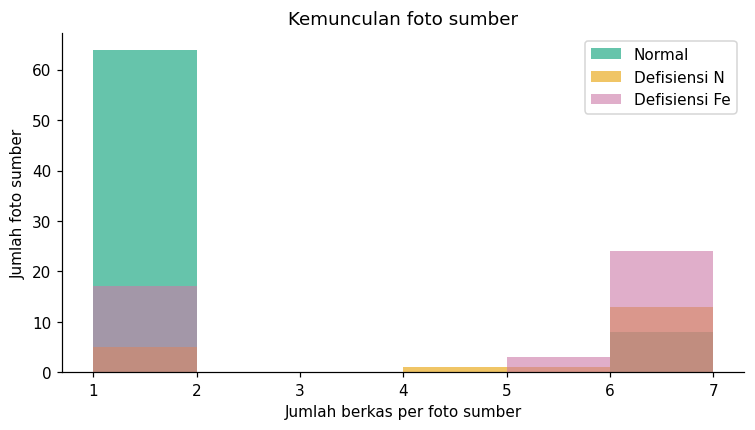

In [4]:
group_table = (
    roboflow.groupby("label")
    .agg(berkas=("image_id", "size"), foto_sumber_unik=("source_group", "nunique"))
    .reindex(CLASSES)
)
group_table["berkas_per_foto_rata2"] = (group_table["berkas"] / group_table["foto_sumber_unik"]).round(2)
per_group = roboflow.groupby(["label", "source_group"]).size().groupby("label")
group_table["berkas_per_foto_median"] = per_group.median().reindex(group_table.index)
group_table["berkas_per_foto_maks"] = per_group.max().reindex(group_table.index)
group_table.loc["total"] = [
    group_table["berkas"].sum(),
    group_table["foto_sumber_unik"].sum(),
    round(group_table["berkas"].sum() / group_table["foto_sumber_unik"].sum(), 2),
    per_group.median().median(),
    per_group.max().max(),
]
display(group_table)
group_table.to_csv(TABLES_DIR / "01_source_groups_per_class.csv")

prefix_classes = roboflow.groupby("prefix")["label"].nunique()
shared_prefixes = prefix_classes[prefix_classes > 1]
print(f"Awalan di lebih dari satu kelas: {len(shared_prefixes)} dari {prefix_classes.size}")

duplicate_hashes = manifest.groupby("sha1").filter(lambda g: len(g) > 1)
conflicts = duplicate_hashes.groupby("sha1")["label"].nunique()
print(f"Berkas dengan isi persis sama  : {len(duplicate_hashes)}")
print(f"Konflik label (isi sama)       : {int((conflicts > 1).sum())}")

fig, ax = plt.subplots(figsize=(8, 4))
for label in CLASSES:
    counts = roboflow[roboflow["label"] == label].groupby("source_group").size()
    ax.hist(counts, bins=range(1, int(counts.max()) + 2), alpha=0.6, label=CLASS_LABEL_ID[label], color=CLASS_COLORS[label])
ax.set_xlabel("Jumlah berkas per foto sumber")
ax.set_ylabel("Jumlah foto sumber")
ax.set_title("Kemunculan foto sumber")
ax.legend()
save_figure(fig, "01_files_per_source_group.png")
plt.show()

##### 2.3 Ukuran gambar

In [5]:
manifest["is_square"] = manifest["width"] == manifest["height"]
size_table = (
    manifest.groupby(["folder", "width", "height"]).size().rename("jumlah").reset_index()
    .sort_values(["folder", "jumlah"], ascending=[True, False])
)
display(size_table)
size_table.to_csv(TABLES_DIR / "01_image_sizes.csv", index=False)
print(f"Gambar tidak persegi: {int((~manifest['is_square']).sum())} dari {len(manifest)}")
print(f"Sisi terpendek / terpanjang: {int(manifest[['width', 'height']].min().min())} / {int(manifest[['width', 'height']].max().max())} px")

,folder,width,height,jumlah
0,fe_deficiency,640,640,159
1,fe_deficiency,1483,2405,1
2,fe_deficiency,1512,2462,1
3,fe_deficiency,2932,3126,1
4,fe_deficiency,2965,3409,1
...,...,...,...,...
85,normal,4507,3240,1
86,normal,4608,2592,1
87,normal,4896,2218,1
88,primary,720,779,6


Gambar tidak persegi: 92 dari 388
Sisi terpendek / terpanjang: 640 / 5184 px


##### 2.4 Manifest

In [6]:
manifest_sha1 = hashlib.sha1("".join(sorted(manifest["sha1"])).encode()).hexdigest()
manifest.drop(columns=["is_square"]).to_csv(PROCESSED_DIR / "manifest.csv", index=False)
print("Baris manifest :", len(manifest))
print("SHA-1 dataset  :", manifest_sha1)

Baris manifest : 388
SHA-1 dataset  : ad8433fffe733d4da01783e1a7750799ebb33ac6


#### 3. Verifikasi Implementasi

##### 3.1 Otsu

$$
\sigma_{B}^{2}(t) = \omega_{0}(t)\,\omega_{1}(t)\,\bigl[\mu_{0}(t) - \mu_{1}(t)\bigr]^{2}, \qquad
t^{*} = \arg\max_{t}\ \sigma_{B}^{2}(t)
$$

dengan $\omega_{0}, \omega_{1}$ proporsi piksel di bawah dan di atas $t$, serta $\mu_{0}, \mu_{1}$ rata-rata nilai kedua kelompok.

In [7]:
otsu_rows = []
for row in manifest.itertuples():
    lab = pp.to_lab_uint8(pp.gaussian_blur(load_resized(row.folder, row.image_id), 5))
    for channel in CHANNELS:
        values, _ = pp.segmentation_values(lab, channel)
        t_manual = pp.otsu_threshold(values)
        t_opencv = int(cv2.threshold(values, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])
        t_skimage = int(threshold_otsu(values))
        otsu_rows.append(
            {
                "channel": channel,
                "t_manual": t_manual,
                "t_opencv": t_opencv,
                "t_skimage": t_skimage,
                "same_mask": bool(np.array_equal(values <= t_manual, values <= t_opencv)),
            }
        )

otsu_df = pd.DataFrame(otsu_rows)
otsu_summary = otsu_df.groupby("channel").agg(
    gambar=("t_manual", "size"),
    sama_dengan_opencv=("same_mask", "sum"),
    selisih_maks_opencv=("t_manual", lambda s: int((s - otsu_df.loc[s.index, "t_opencv"]).abs().max())),
    selisih_maks_skimage=("t_manual", lambda s: int((s - otsu_df.loc[s.index, "t_skimage"]).abs().max())),
).reindex(CHANNELS)
display(otsu_summary)
otsu_summary.to_csv(TABLES_DIR / "01_otsu_verification.csv")
print("LULUS" if (otsu_summary["sama_dengan_opencv"] == otsu_summary["gambar"]).all() else "GAGAL", "Otsu manual = OpenCV")

,gambar,sama_dengan_opencv,selisih_maks_opencv,selisih_maks_skimage
channel,,,,
a,388,388,0,0
b,388,388,0,0
chroma,388,388,0,0


LULUS Otsu manual = OpenCV


##### 3.2 Konversi CIELAB

$$
L^{*} = \frac{L_{8} \cdot 100}{255}, \qquad a^{*} = a_{8} - 128, \qquad b^{*} = b_{8} - 128
$$

In [8]:
lab_rows = []
for row in manifest.iloc[rng.choice(len(manifest), size=min(20, len(manifest)), replace=False)].itertuples():
    resized = load_resized(row.folder, row.image_id)
    difference = np.abs(pp.lab_uint8_to_physical(pp.to_lab_uint8(resized)) - rgb2lab(to_rgb(resized)))
    lab_rows.append({**{f"mean_{n}": difference[..., i].mean() for i, n in enumerate("Lab")},
                     **{f"max_{n}": difference[..., i].max() for i, n in enumerate("Lab")}})

lab_check = pd.DataFrame(lab_rows)
lab_summary = pd.DataFrame(
    {
        "rata-rata selisih": lab_check[["mean_L", "mean_a", "mean_b"]].mean().values,
        "selisih terbesar": lab_check[["max_L", "max_a", "max_b"]].max().values,
    },
    index=["L*", "a*", "b*"],
).round(3)
display(lab_summary)
lab_summary.to_csv(TABLES_DIR / "01_lab_conversion_check.csv")
print("LULUS" if lab_summary["rata-rata selisih"].max() < 1.0 else "GAGAL", "Konversi Lab rata-rata selisih < 1")

,rata-rata selisih,selisih terbesar
L*,0.106,0.570
a*,0.262,2.619
b*,0.244,1.523


LULUS Konversi Lab rata-rata selisih < 1


#### 4. Pemilihan Kanal Segmentasi

##### 4.1 Kriteria

$$
D(M_{1}, M_{2}) = \frac{2\,|M_{1} \cap M_{2}|}{|M_{1}| + |M_{2}|}, \qquad
C^{*} = \sqrt{a^{*2} + b^{*2}}
$$

$$
\bar{D}_{c}(i) = \frac{1}{2} \sum_{c' \ne c} D\bigl(M_{c}^{(i)}, M_{c'}^{(i)}\bigr), \qquad
\text{selisih}(i) \iff \min_{c < c'} D\bigl(M_{c}^{(i)}, M_{c'}^{(i)}\bigr) < 0{,}85
$$

$$
o(i) = \arg\min_{c}\ \bar{D}_{c}(i), \qquad
s_{c,y} = \frac{\bigl|\{\, i \in \text{kelas } y : \text{selisih}(i),\ o(i) = c \,\}\bigr|}{N_{y}}, \qquad
s_{c} = \max_{y}\ s_{c,y}
$$

$$
T = \bigl\{\, c : s_{c} \le \min_{c'} s_{c'} + 0{,}05 \,\bigr\}, \qquad
c^{*} = \text{kanal pertama dari } T \text{ menurut urutan } (a,\ b,\ \mathrm{chroma})
$$

dengan $N_{y}$ jumlah gambar kelas $y$. Kanal dinilai dari kelas yang paling terdampak, sehingga kebocoran yang terkonsentrasi pada satu kelas tidak tertutupi oleh kelas lain.

##### 4.2 Perhitungan pada seluruh dataset Roboflow

In [9]:
PAIRS = [("a", "b"), ("a", "chroma"), ("b", "chroma")]

channel_rows = []
for row in roboflow.itertuples():
    resized = load_resized(row.folder, row.image_id)
    masks = {c: pp.segment(resized, pp.PipelineConfig(segmentation_channel=c))[0] for c in CHANNELS}
    pair_dice = {pair: dice(masks[pair[0]], masks[pair[1]]) for pair in PAIRS}
    mean_dice = {c: float(np.mean([v for pair, v in pair_dice.items() if c in pair])) for c in CHANNELS}
    disagree = min(pair_dice.values()) < DICE_AGREEMENT
    channel_rows.append(
        {
            "image_id": row.image_id,
            "folder": row.folder,
            "label": row.label,
            "source_group": row.source_group,
            **{f"area_{c}": masks[c].mean() for c in CHANNELS},
            "dice_a_b": pair_dice[("a", "b")],
            "dice_a_chroma": pair_dice[("a", "chroma")],
            "dice_b_chroma": pair_dice[("b", "chroma")],
            "min_dice": min(pair_dice.values()),
            "outlier": min(mean_dice, key=mean_dice.get) if disagree else "",
        }
    )

channel_df = pd.DataFrame(channel_rows)
channel_df.round(4).to_csv(TABLES_DIR / "01_channel_comparison_images.csv", index=False)

area_table = channel_df.groupby("label")[[f"area_{c}" for c in CHANNELS]].median().reindex(CLASSES).round(3)
area_table.columns = [f"median luas {c}" for c in CHANNELS]
dice_table = channel_df.groupby("label")[["dice_a_b", "dice_a_chroma", "dice_b_chroma"]].mean().reindex(CLASSES).round(3)
outlier_table = pd.crosstab(channel_df["label"], channel_df["outlier"]).reindex(index=CLASSES, columns=list(CHANNELS), fill_value=0)
outlier_table.columns = [f"menyimpang {c}" for c in CHANNELS]

channel_summary = pd.concat([area_table, dice_table, outlier_table], axis=1)
display(channel_summary)
channel_summary.to_csv(TABLES_DIR / "01_channel_comparison_summary.csv")

,median luas a,median luas b,median luas chroma,dice_a_b,dice_a_chroma,dice_b_chroma,menyimpang a,menyimpang b,menyimpang chroma
label,,,,,,,,,
normal,0.390,0.388,0.384,0.973,0.955,0.962,2,0,8
n_deficiency,0.422,0.398,0.407,0.922,0.924,0.995,11,0,0
fe_deficiency,0.425,0.431,0.432,0.975,0.970,0.985,0,0,0


##### 4.3 Kanal terpilih

In [10]:
outlier_counts = {c: int((channel_df["outlier"] == c).sum()) for c in CHANNELS}
class_sizes = channel_df.groupby("label").size().reindex(CLASSES)
share_table = pd.DataFrame(
    {c: channel_df[channel_df["outlier"] == c].groupby("label").size().reindex(CLASSES).fillna(0) / class_sizes for c in CHANNELS}
)
worst_share = share_table.max()
tied = [c for c in CHANNEL_PREFERENCE if worst_share[c] <= worst_share.min() + TIE_MARGIN]
auto_channel = tied[0]
selected_channel = auto_channel if SEGMENTATION_CHANNEL == "auto" else SEGMENTATION_CHANNEL

display((share_table * 100).round(1).rename_axis("persen gambar menyimpang"))
share_table.round(4).to_csv(TABLES_DIR / "01_channel_outlier_share.csv")
print("Jumlah gambar          :", len(channel_df))
print("Gambar berselisih      :", int((channel_df["outlier"] != "").sum()))
print("Jumlah menyimpang      :", outlier_counts)
print("s per kanal (kelas terburuk):", {c: round(float(v), 4) for c, v in worst_share.items()})
print("Kanal yang seri        :", tied)
print("Kanal pilihan otomatis :", auto_channel)
print("Kanal yang dipakai     :", selected_channel)

,a,b,chroma
persen gambar menyimpang,,,
normal,1.8,0.0,7.1
n_deficiency,12.0,0.0,0.0
fe_deficiency,0.0,0.0,0.0


Jumlah gambar          : 380
Gambar berselisih      : 21
Jumlah menyimpang      : {'a': 13, 'b': 0, 'chroma': 8}
s per kanal (kelas terburuk): {'a': 0.1196, 'b': 0.0, 'chroma': 0.0714}
Kanal yang seri        : ['b']
Kanal pilihan otomatis : b
Kanal yang dipakai     : b


##### 4.4 Gambar dengan selisih kanal terbesar

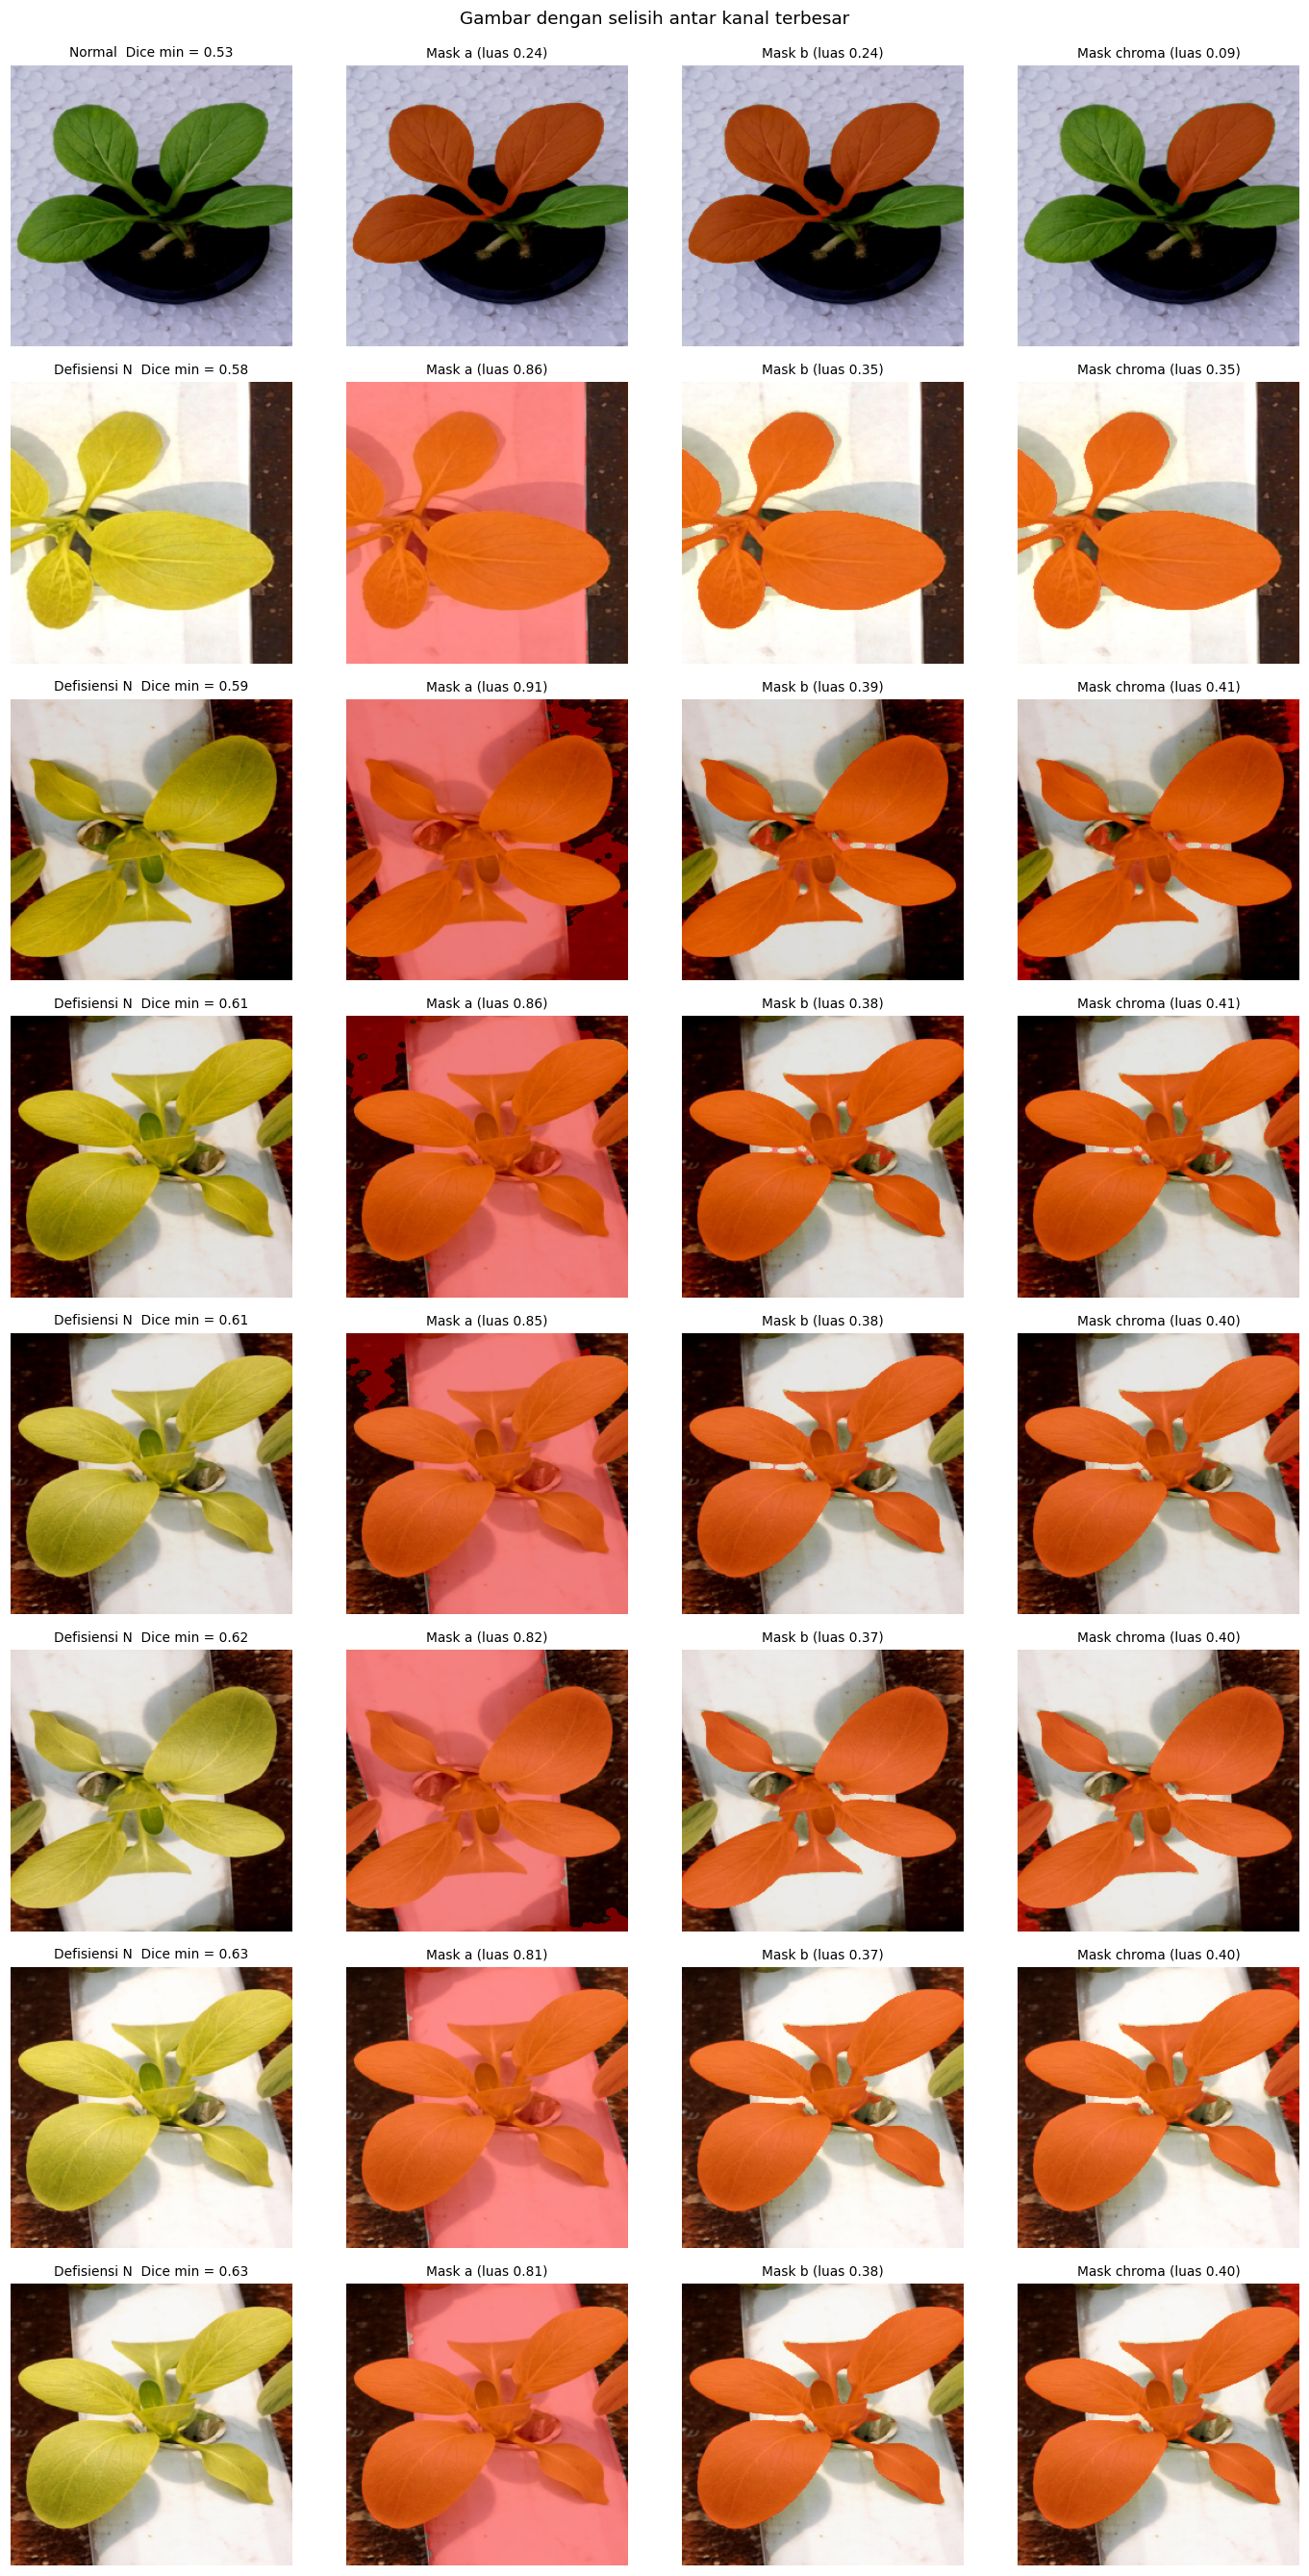

In [11]:
worst = channel_df.sort_values("min_dice").head(GALLERY_SIZE)
fig, axes = plt.subplots(len(worst), 4, figsize=(13, 3.1 * len(worst)))
axes = np.atleast_2d(axes)
for r, row in enumerate(worst.itertuples()):
    resized = load_resized(row.folder, row.image_id)
    axes[r, 0].imshow(to_rgb(resized))
    axes[r, 0].set_title(f"{CLASS_LABEL_ID[row.label]}  Dice min = {row.min_dice:.2f}", fontsize=9)
    for c, channel in enumerate(CHANNELS, start=1):
        mask = pp.segment(resized, pp.PipelineConfig(segmentation_channel=channel))[0]
        axes[r, c].imshow(tint_overlay(resized, mask))
        axes[r, c].set_title(f"Mask {channel} (luas {mask.mean():.2f})", fontsize=9)
    for ax in axes[r]:
        ax.axis("off")
fig.suptitle("Gambar dengan selisih antar kanal terbesar", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save_figure(fig, "01_channel_disagreement.png")
plt.show()

#### 5. Aturan Komponen Mask

##### 5.1 Definisi

$$
\text{largest: } K = \{\arg\max_{k} A_{k}\}, \qquad
\text{relative: } K = \{\, k : A_{k} \ge \rho \cdot \max_{j} A_{j} \,\}, \quad \rho = 0{,}05
$$

dengan $A_{k}$ luas komponen terhubung ke-$k$ setelah opening dan closing, dan $K$ himpunan komponen yang dipertahankan.

$$
\text{pertambahan luas} = \frac{|M_{relative}|}{|M_{largest}|} - 1
$$

##### 5.2 Perbandingan pada seluruh dataset Roboflow

In [12]:
probe_config = pp.PipelineConfig(segmentation_channel=selected_channel)
component_rows = []
for row in roboflow.itertuples():
    resized = load_resized(row.folder, row.image_id)
    raw_mask = pp.segment(resized, probe_config)[2]["raw_mask"]
    closed = pp.open_close(raw_mask, probe_config.morphology_size)
    largest = pp.select_components(closed, "largest")
    relative = pp.select_components(closed, "relative", MIN_COMPONENT_RATIO)
    component_rows.append(
        {
            "image_id": row.image_id,
            "folder": row.folder,
            "label": row.label,
            "components": cv2.connectedComponents(closed, connectivity=8)[0] - 1,
            "kept_relative": cv2.connectedComponents(relative, connectivity=8)[0] - 1,
            "area_largest": largest.mean(),
            "area_relative": relative.mean(),
            "gain": relative.sum() / max(largest.sum(), 1) - 1.0,
        }
    )

component_df = pd.DataFrame(component_rows)
component_df.round(4).to_csv(TABLES_DIR / "01_component_rule_images.csv", index=False)
component_summary = (
    component_df.groupby("label")
    .agg(
        komponen_rata2=("components", "mean"),
        dipertahankan_relative=("kept_relative", "mean"),
        median_pertambahan_luas=("gain", "median"),
        persen_gambar_bertambah_10=("gain", lambda s: (s > 0.10).mean() * 100),
    )
    .reindex(CLASSES)
    .round(3)
)
display(component_summary)
component_summary.to_csv(TABLES_DIR / "01_component_rule_summary.csv")
print("Aturan komponen yang dipakai:", COMPONENT_RULE)

,komponen_rata2,dipertahankan_relative,median_pertambahan_luas,persen_gambar_bertambah_10
label,,,,
normal,2.250,1.089,0.0,6.250
n_deficiency,1.772,1.174,0.0,3.261
fe_deficiency,3.062,1.165,0.0,9.091


Aturan komponen yang dipakai: relative


##### 5.3 Gambar dengan pertambahan luas terbesar

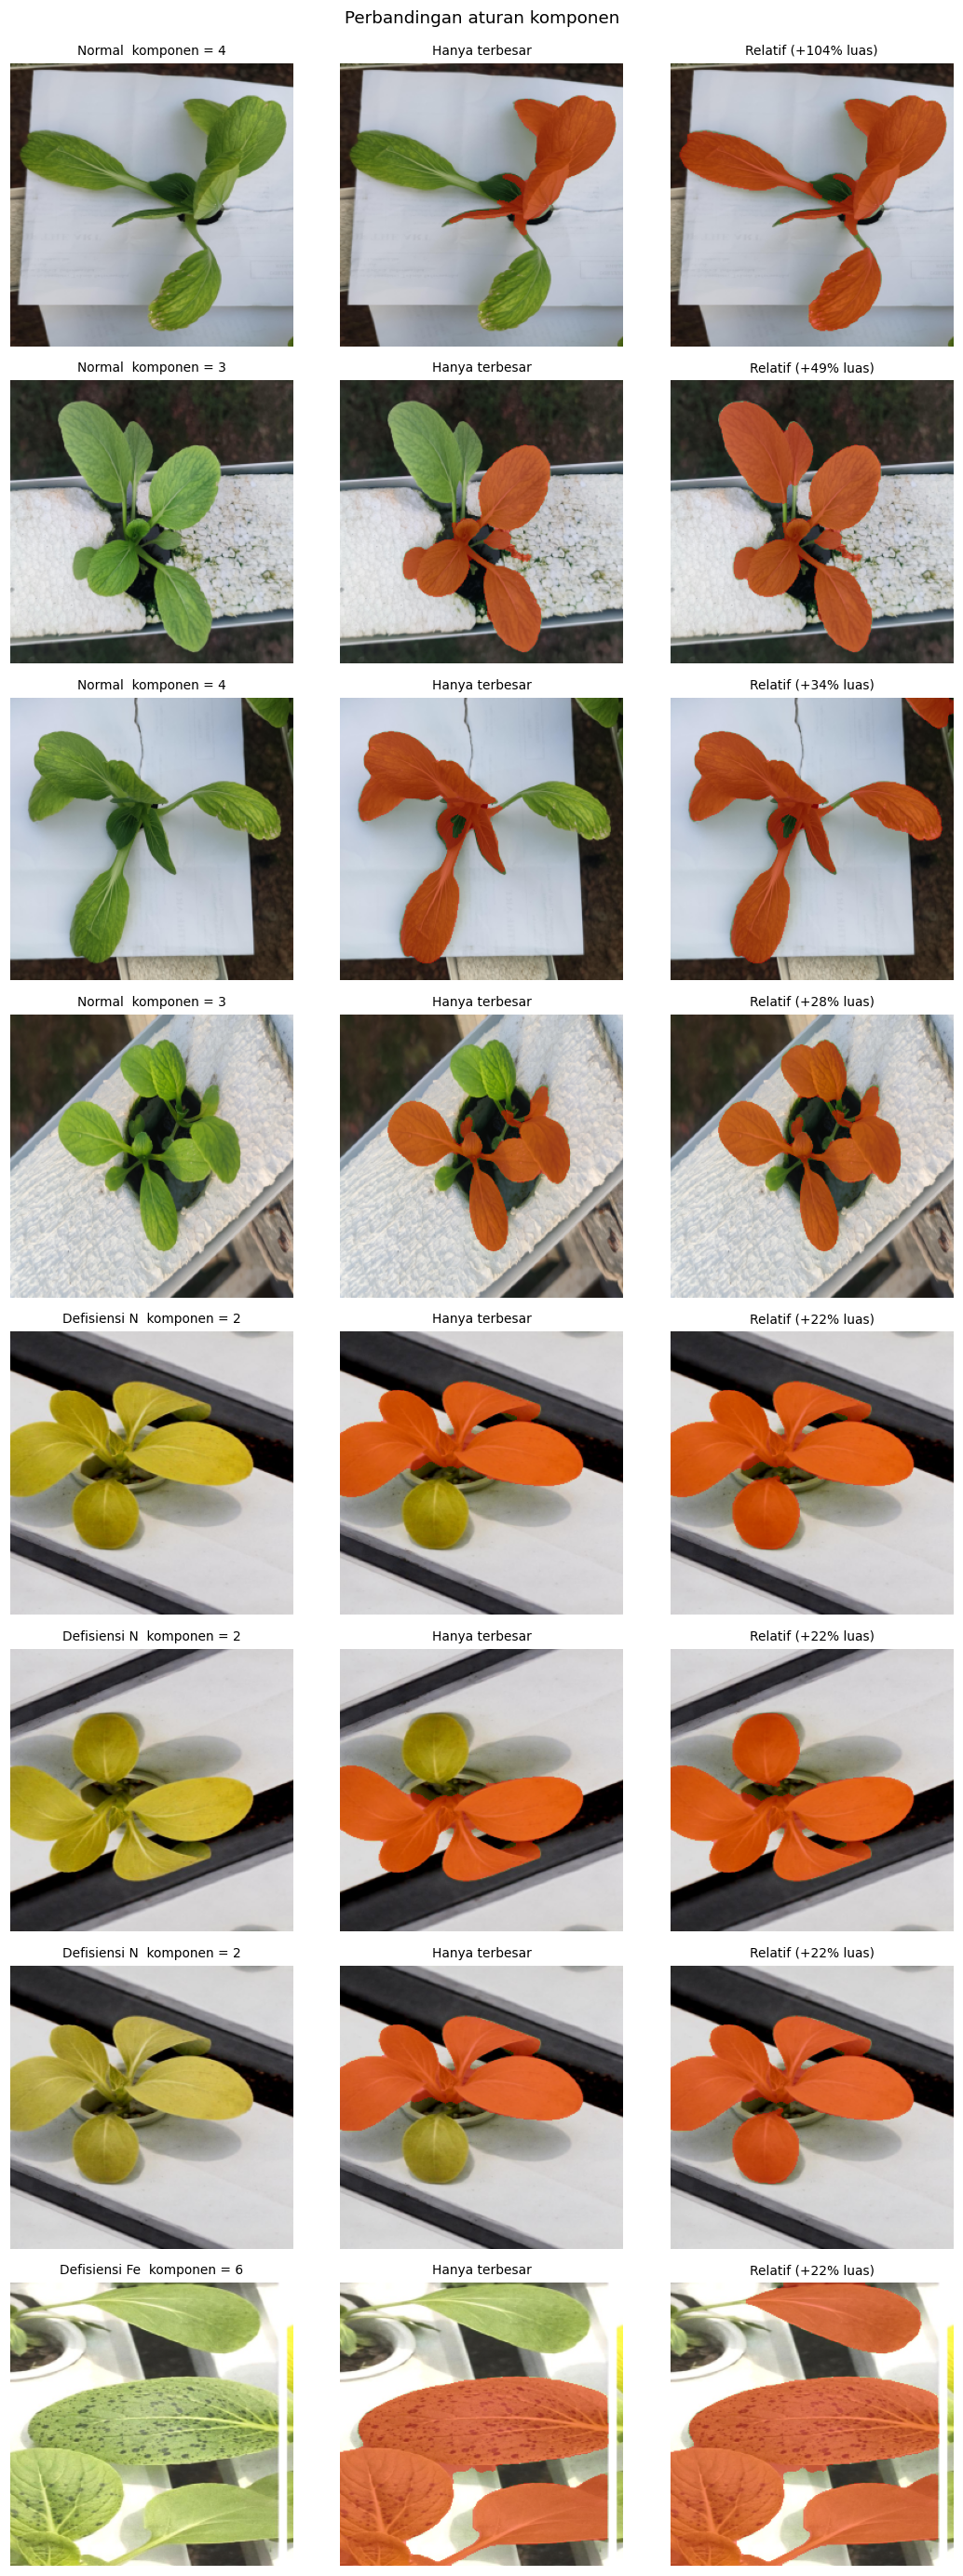

Konfigurasi dasar: {'resize': 256, 'blur_kernel': 5, 'morphology_size': 5, 'segmentation_channel': 'b', 'component_rule': 'relative', 'min_component_ratio': 0.05, 'min_leaf_area_ratio': 0.0, 'max_leaf_area_ratio': 1.0}


In [13]:
top = component_df.sort_values("gain", ascending=False).head(GALLERY_SIZE)
fig, axes = plt.subplots(len(top), 3, figsize=(10, 3.2 * len(top)))
axes = np.atleast_2d(axes)
for r, row in enumerate(top.itertuples()):
    resized = load_resized(row.folder, row.image_id)
    raw_mask = pp.segment(resized, probe_config)[2]["raw_mask"]
    closed = pp.open_close(raw_mask, probe_config.morphology_size)
    axes[r, 0].imshow(to_rgb(resized))
    axes[r, 0].set_title(f"{CLASS_LABEL_ID[row.label]}  komponen = {row.components}", fontsize=9)
    axes[r, 1].imshow(tint_overlay(resized, pp.select_components(closed, "largest")))
    axes[r, 1].set_title("Hanya terbesar", fontsize=9)
    axes[r, 2].imshow(tint_overlay(resized, pp.select_components(closed, "relative", MIN_COMPONENT_RATIO)))
    axes[r, 2].set_title(f"Relatif (+{row.gain:.0%} luas)", fontsize=9)
    for ax in axes[r]:
        ax.axis("off")
fig.suptitle("Perbandingan aturan komponen", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save_figure(fig, "01_component_rule_gallery.png")
plt.show()

config_base = pp.PipelineConfig(
    segmentation_channel=selected_channel,
    component_rule=COMPONENT_RULE,
    min_component_ratio=MIN_COMPONENT_RATIO,
)
print("Konfigurasi dasar:", config_base.to_dict())

#### 6. Tahap Pipeline

##### 6.1 Tahap 1: Resize

$$
I'(x', y') = \frac{1}{|W(x', y')|} \sum_{(x, y) \in W(x', y')} I(x, y)
$$

dengan $W(x', y')$ himpunan piksel sumber yang tercakup oleh piksel keluaran $(x', y')$.

##### 6.2 Tahap 2: Gaussian blur

$$
G(x, y) = \frac{1}{2\pi\sigma^{2}} \exp\left(-\frac{x^{2} + y^{2}}{2\sigma^{2}}\right), \qquad
\sigma = 0{,}3\left(\frac{k - 1}{2} - 1\right) + 0{,}8
$$

dengan $k = 5$ sehingga $\sigma = 1{,}1$.

##### 6.3 Tahap 3: Konversi CIELAB

$$
L^{*} = 116\, f\!\left(\frac{Y}{Y_{n}}\right) - 16, \qquad
a^{*} = 500\left[f\!\left(\frac{X}{X_{n}}\right) - f\!\left(\frac{Y}{Y_{n}}\right)\right], \qquad
b^{*} = 200\left[f\!\left(\frac{Y}{Y_{n}}\right) - f\!\left(\frac{Z}{Z_{n}}\right)\right]
$$

$$
f(t) = \begin{cases} t^{1/3} & t > (6/29)^{3} \\ \dfrac{t}{3\,(6/29)^{2}} + \dfrac{4}{29} & \text{lainnya} \end{cases}
$$

##### 6.4 Tahap 4: Threshold Otsu

$$
M(p) = \begin{cases} 1 & v(p) \le t^{*} \quad \text{(kanal } a\text{)} \\ 1 & v(p) > t^{*} \quad \text{(kanal } b \text{ dan chroma)} \\ 0 & \text{lainnya} \end{cases}
$$

dengan $v(p)$ nilai kanal terpilih pada piksel $p$ dan $t^{*}$ ambang Otsu dari bagian 3.1.

##### 6.5 Tahap 5: Morfologi

$$
A \circ B = (A \ominus B) \oplus B \quad \text{(opening)}, \qquad
A \bullet B = (A \oplus B) \ominus B \quad \text{(closing)}
$$

dengan $B$ elips 5 x 5. Komponen yang dipertahankan mengikuti aturan pada bagian 5.1.

##### 6.6 Tahap 6: Segmentasi

$$
I_{seg}(p) = I(p) \cdot M(p)
$$

##### 6.7 Tahap 7: Kontur dan bounding box

$$
r = \frac{|M|}{256 \times 256}
$$

##### 6.8 Tahap 8: Ekstraksi warna

$$
\mu_{c} = \frac{1}{|M|} \sum_{p \in M} I_{c}(p), \qquad c \in \{R, G, B, L^{*}, a^{*}, b^{*}\}
$$

##### 6.9 Contoh satu foto per kelas

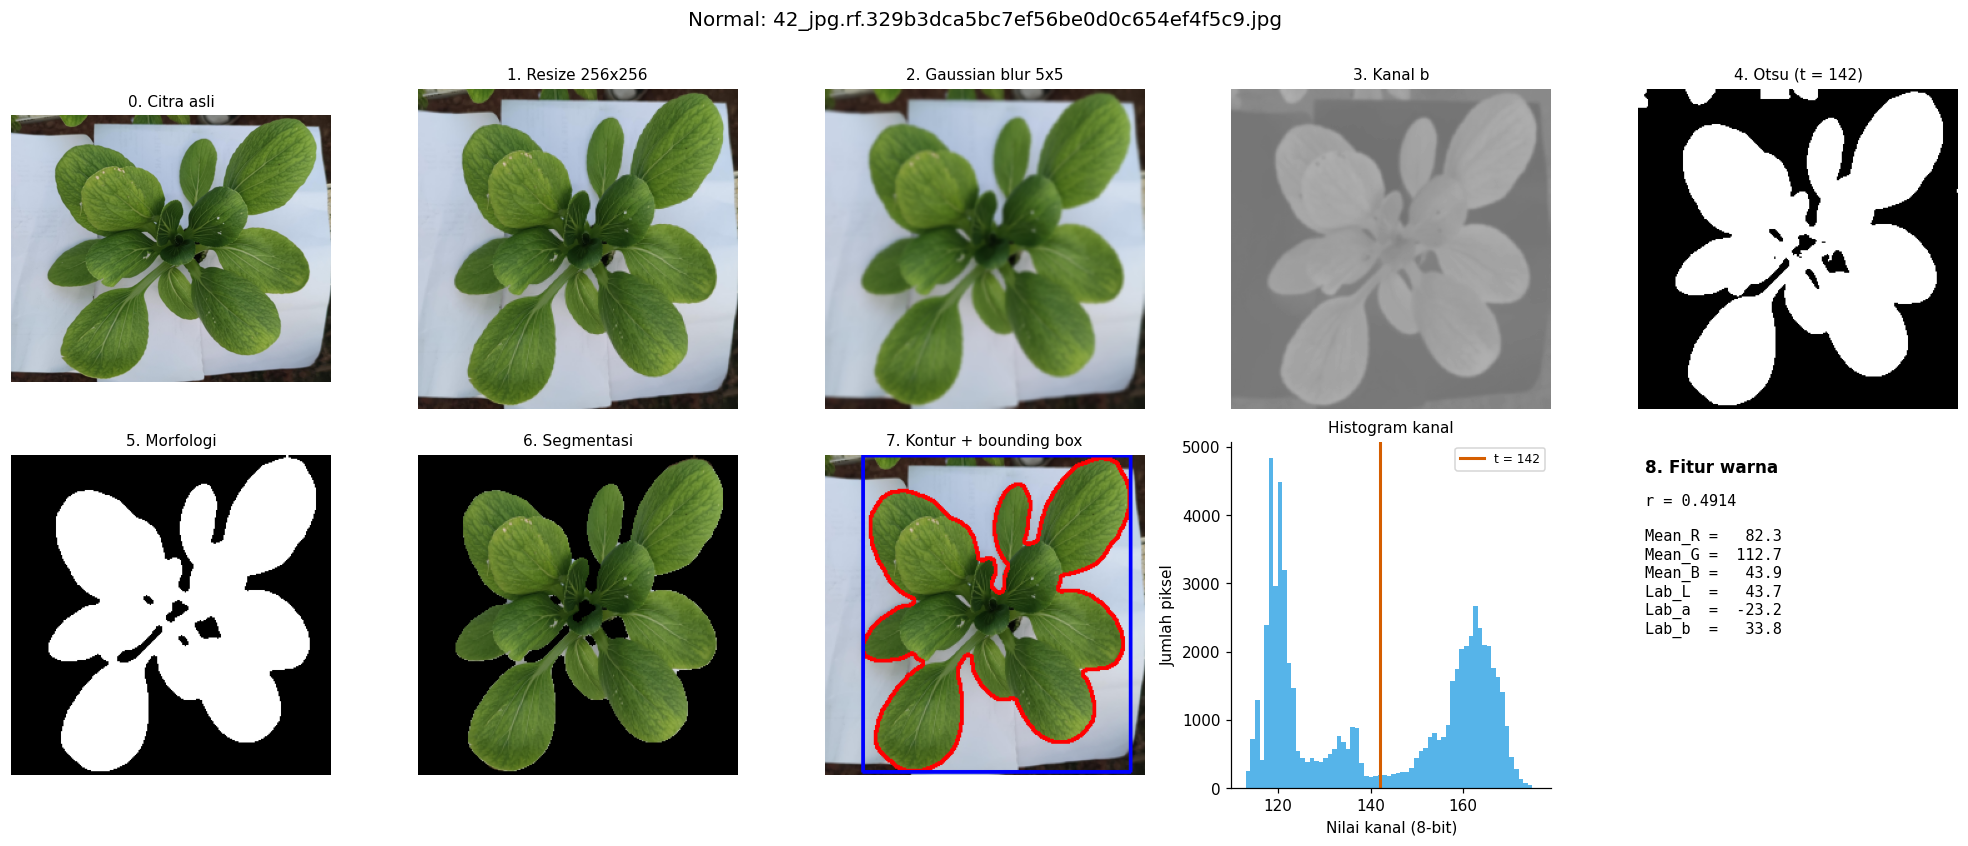

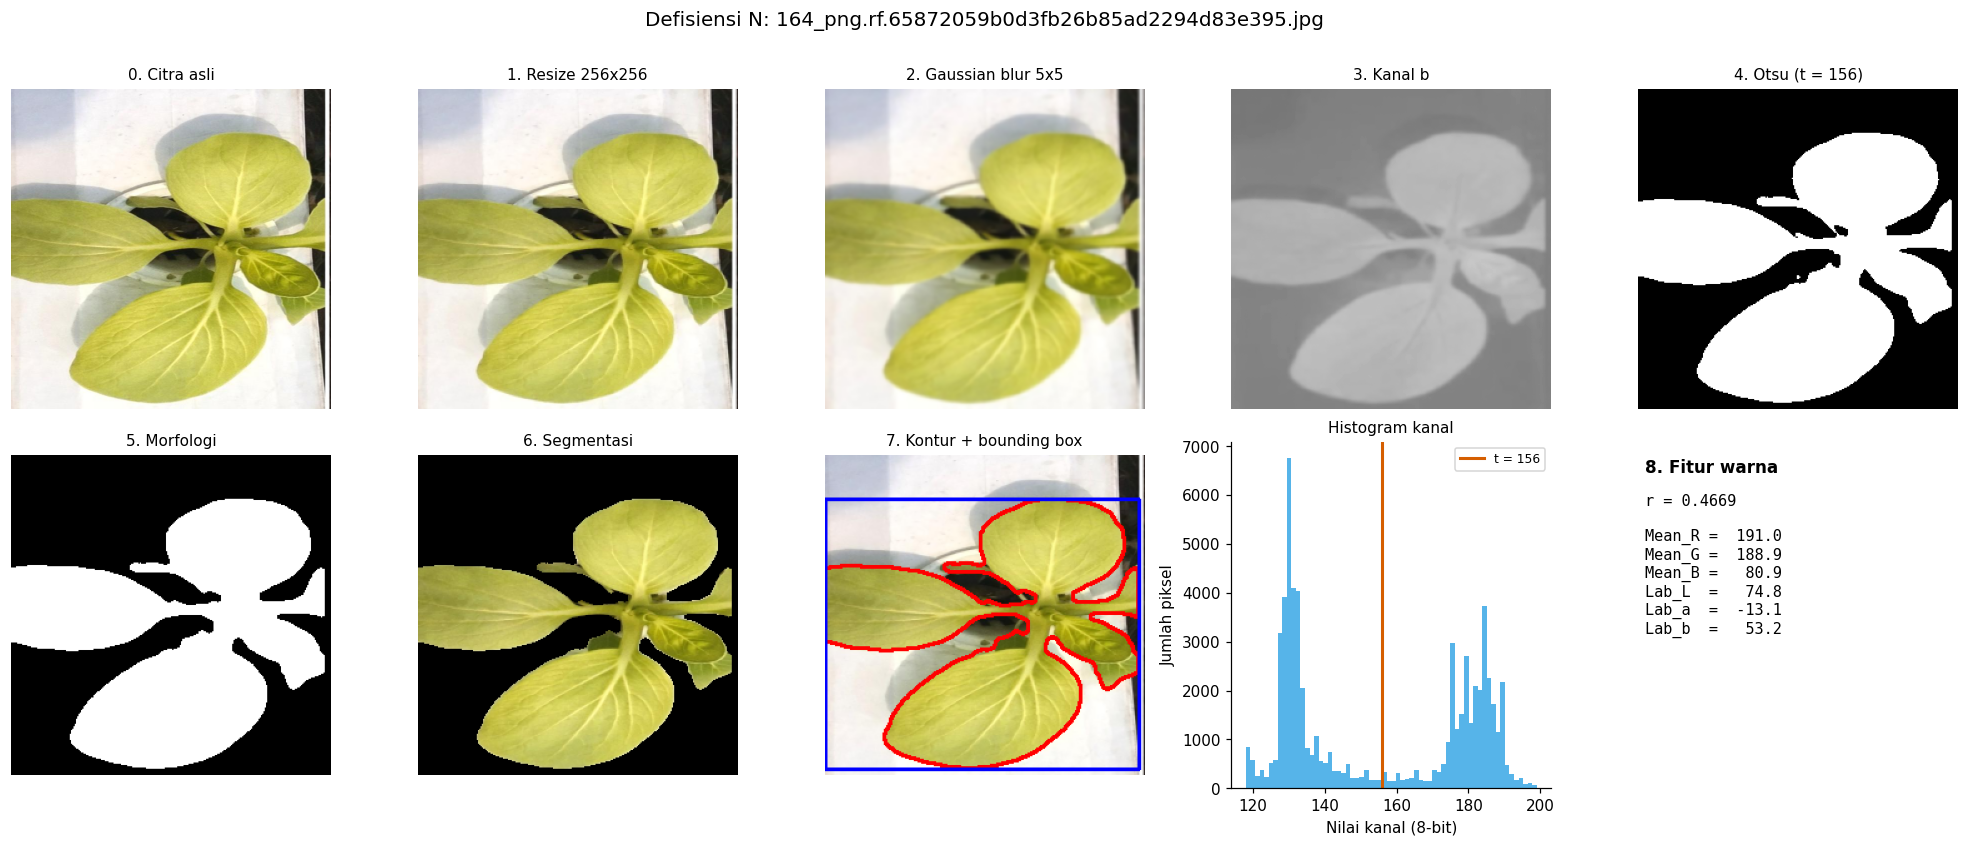

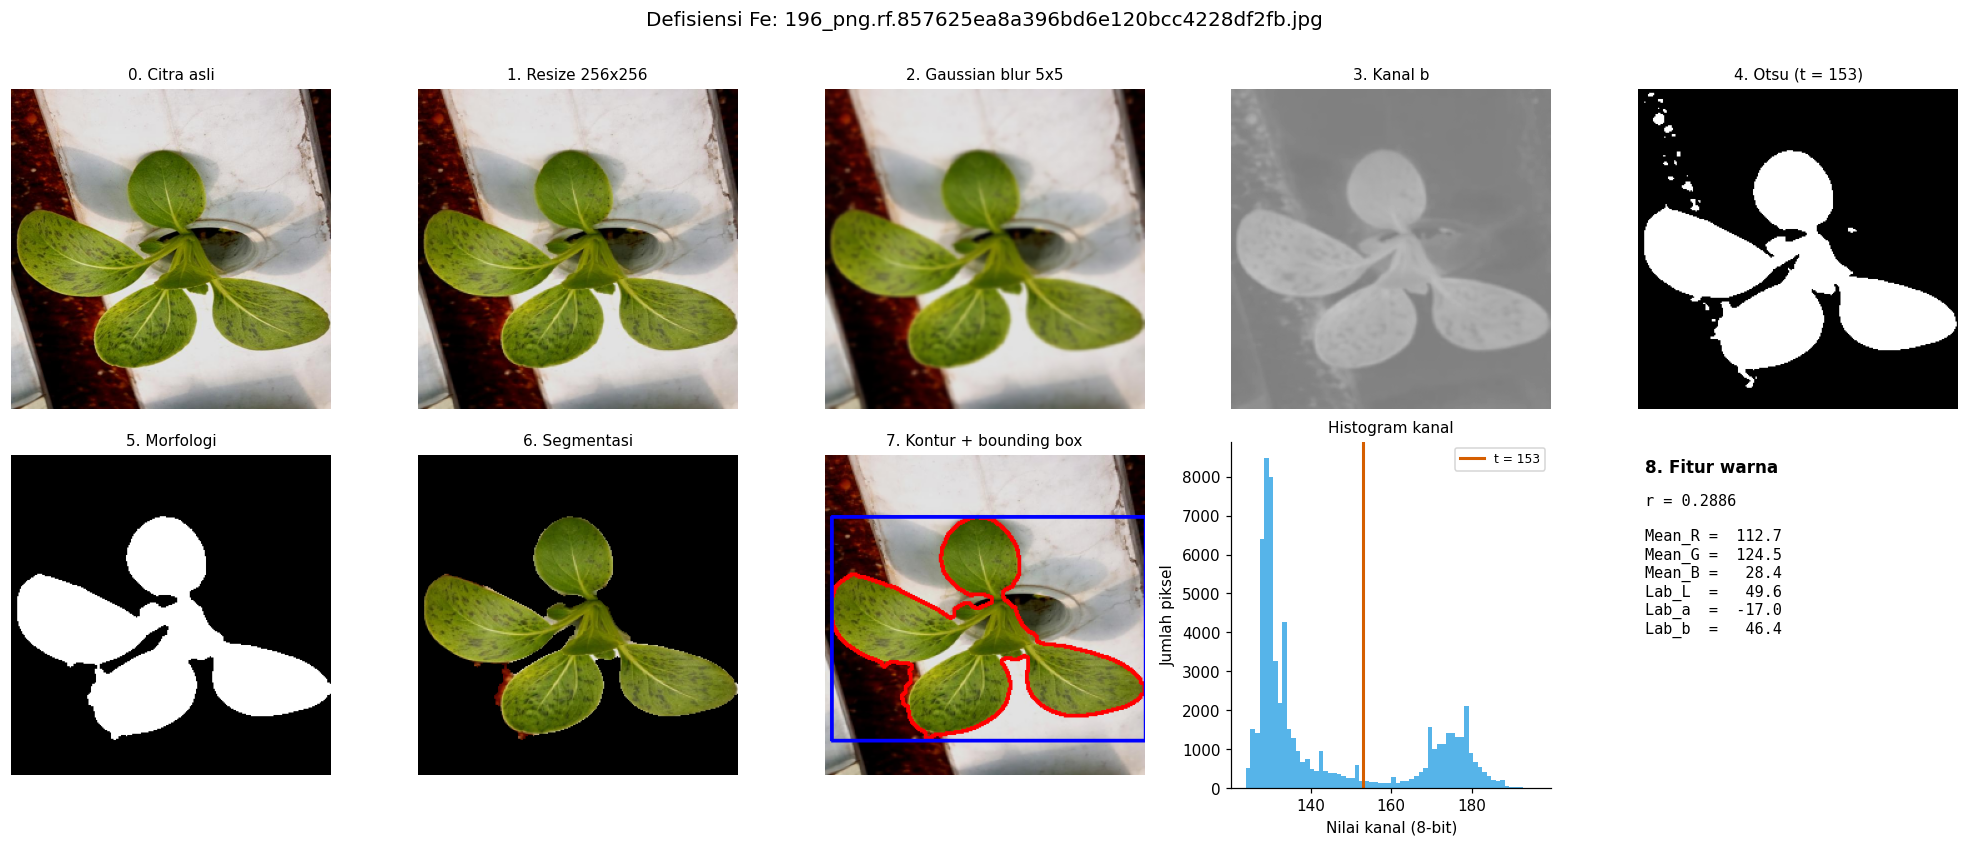

In [14]:
def plot_pipeline(row, save_name: str) -> None:
    original = pp.read_image_bgr(RAW_DIR / row.folder / row.image_id)
    result = pp.process_image(original, config_base, keep_steps=True)
    steps = result.steps

    fig, axes = plt.subplots(2, 5, figsize=(18, 7.8))
    flat = axes.ravel()
    panels = [
        ("0. Citra asli", to_rgb(original), None),
        (f"1. Resize {config_base.resize}x{config_base.resize}", to_rgb(steps["resized"]), None),
        (f"2. Gaussian blur {config_base.blur_kernel}x{config_base.blur_kernel}", to_rgb(steps["blurred"]), None),
        (f"3. Kanal {config_base.segmentation_channel}", steps["segmentation_values"], "gray"),
        (f"4. Otsu (t = {result.threshold})", steps["raw_mask"] * 255, "gray"),
        ("5. Morfologi", steps["mask"] * 255, "gray"),
        ("6. Segmentasi", to_rgb(steps["segmented"]), None),
        ("7. Kontur + bounding box", to_rgb(steps["overlay"]), None),
    ]
    for ax, (title, image, cmap) in zip(flat[:8], panels):
        ax.imshow(image, cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    flat[8].hist(steps["segmentation_values"].ravel(), bins=64, color="#56B4E9")
    flat[8].axvline(result.threshold, color="#D55E00", linewidth=2, label=f"t = {result.threshold}")
    flat[8].set_title("Histogram kanal", fontsize=10)
    flat[8].set_xlabel("Nilai kanal (8-bit)")
    flat[8].set_ylabel("Jumlah piksel")
    flat[8].legend(fontsize=8)

    flat[9].axis("off")
    lines = [f"r = {result.mask_area_ratio:.4f}", ""]
    lines += [f"{name:7s}= {value:6.1f}" for name, value in result.features.items()]
    flat[9].text(0.02, 0.95, "8. Fitur warna", fontsize=11, fontweight="bold", va="top")
    flat[9].text(0.02, 0.85, "\n".join(lines), fontsize=10, va="top", family="monospace")

    fig.suptitle(f"{CLASS_LABEL_ID[row.label]}: {row.image_id}", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    save_figure(fig, save_name)
    plt.show()


for label in CLASSES:
    candidates = roboflow[roboflow["label"] == label]
    plot_pipeline(candidates.iloc[int(rng.integers(len(candidates)))], f"01_pipeline_{label}.png")

#### 7. Pemrosesan Seluruh Dataset

##### 7.1 Menjalankan pipeline

In [15]:
def run_pipeline(frame: pd.DataFrame, config: pp.PipelineConfig) -> pd.DataFrame:
    rows = []
    for position, row in enumerate(frame.itertuples(), start=1):
        started = time.perf_counter()
        bgr = pp.read_image_bgr(RAW_DIR / row.folder / row.image_id)
        result = pp.process_image(bgr, config, keep_steps=True)
        elapsed_ms = (time.perf_counter() - started) * 1000.0

        mask_path = MASK_DIR / row.folder / (Path(row.image_id).stem + ".png")
        mask_path.parent.mkdir(parents=True, exist_ok=True)
        ok, encoded = cv2.imencode(".png", result.steps["mask"] * 255)
        if ok:
            encoded.tofile(str(mask_path))

        rows.append(
            {
                "image_id": row.image_id,
                "source_group": row.source_group,
                "label": row.label,
                "origin": row.origin,
                "folder": row.folder,
                "mask_area_ratio": result.mask_area_ratio,
                "otsu_threshold": result.threshold,
                **result.features,
                "time_ms": elapsed_ms,
            }
        )
        if position % 100 == 0 or position == len(frame):
            print(f"  {position}/{len(frame)} foto selesai")
    return pd.DataFrame(rows)


started_all = time.perf_counter()
features_raw = run_pipeline(manifest, config_base)
total_seconds = time.perf_counter() - started_all
print(f"Total {total_seconds:.1f} detik, {total_seconds / len(features_raw) * 1000:.0f} ms per foto (termasuk baca berkas dan simpan mask)")

  100/388 foto selesai
  200/388 foto selesai
  300/388 foto selesai
  388/388 foto selesai
Total 8.9 detik, 23 ms per foto (termasuk baca berkas dan simpan mask)


##### 7.2 Batas luas daun

$$
r_{min} = \max\bigl(0{,}02,\ Q_{1} - k\,\mathrm{IQR}\bigr), \qquad
r_{max} = \min\bigl(0{,}98,\ Q_{3} + k\,\mathrm{IQR}\bigr), \qquad
\mathrm{IQR} = Q_{3} - Q_{1}
$$

dengan $Q_{1}$ dan $Q_{3}$ kuartil pertama dan ketiga dari $r$ pada foto Roboflow, dan $k$ bernilai 1,5 atau 3.

,k,r_min,r_max,dibuang,Normal,Defisiensi N,Defisiensi Fe
0,1.5,0.1742,0.6475,19,8,6,5
1,3.0,0.0200,0.8250,0,0,0,0


Q1 = 0.3517  Q3 = 0.4700  IQR = 0.1183  median = 0.4192
k yang dipakai = 3.0: r_min = 0.02, r_max = 0.825


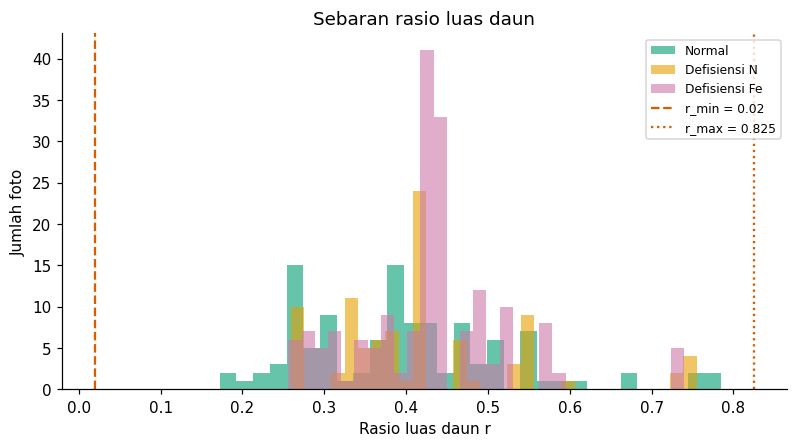

In [16]:
roboflow_ratios = features_raw.loc[features_raw["origin"] == "roboflow", "mask_area_ratio"]
q1, q3 = (float(v) for v in roboflow_ratios.quantile([0.25, 0.75]))
iqr = q3 - q1


def fences(k: float) -> tuple[float, float]:
    return round(max(0.02, q1 - k * iqr), 4), round(min(0.98, q3 + k * iqr), 4)


fence_rows = []
for k in (1.5, 3.0):
    low, high = fences(k)
    flagged = features_raw[(features_raw["origin"] == "roboflow") & ((features_raw["mask_area_ratio"] < low) | (features_raw["mask_area_ratio"] > high))]
    row = {"k": k, "r_min": low, "r_max": high, "dibuang": len(flagged)}
    row.update({CLASS_LABEL_ID[c]: int((flagged["label"] == c).sum()) for c in CLASSES})
    fence_rows.append(row)
fence_table = pd.DataFrame(fence_rows)
display(fence_table)
fence_table.to_csv(TABLES_DIR / "01_area_fences.csv", index=False)

min_leaf_area_ratio, max_leaf_area_ratio = fences(TUKEY_K)
config_final = dataclasses.replace(
    config_base, min_leaf_area_ratio=min_leaf_area_ratio, max_leaf_area_ratio=max_leaf_area_ratio
)
print(f"Q1 = {q1:.4f}  Q3 = {q3:.4f}  IQR = {iqr:.4f}  median = {roboflow_ratios.median():.4f}")
print(f"k yang dipakai = {TUKEY_K}: r_min = {min_leaf_area_ratio}, r_max = {max_leaf_area_ratio}")

features_df = features_raw.copy()
features_df["qc_status"] = features_df["mask_area_ratio"].apply(lambda value: pp.qc_status(value, config_final))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for label in CLASSES:
    values = features_df[(features_df["label"] == label) & (features_df["origin"] == "roboflow")]["mask_area_ratio"]
    ax.hist(values, bins=30, alpha=0.6, color=CLASS_COLORS[label], label=CLASS_LABEL_ID[label])
ax.axvline(min_leaf_area_ratio, color="#D55E00", linestyle="--", label=f"r_min = {min_leaf_area_ratio}")
ax.axvline(max_leaf_area_ratio, color="#D55E00", linestyle=":", label=f"r_max = {max_leaf_area_ratio}")
ax.set_xlabel("Rasio luas daun r")
ax.set_ylabel("Jumlah foto")
ax.set_title("Sebaran rasio luas daun")
ax.legend(fontsize=8)
save_figure(fig, "01_mask_area_ratio.png")
plt.show()

##### 7.3 Hasil kontrol kualitas

In [17]:
roboflow_features = features_df[features_df["origin"] == "roboflow"]
qc_table = (
    pd.crosstab(roboflow_features["label"], roboflow_features["qc_status"])
    .reindex(index=CLASSES, columns=[pp.QC_OK, pp.QC_INVALID_LEAF], fill_value=0)
)
qc_table["total"] = qc_table.sum(axis=1)
qc_table["persen_dibuang"] = (qc_table[pp.QC_INVALID_LEAF] / qc_table["total"] * 100).round(1)
display(qc_table)
qc_table.to_csv(TABLES_DIR / "01_qc_per_class.csv")

group_qc = (
    roboflow_features.groupby(["label", "source_group"])["qc_status"]
    .agg(total="size", valid=lambda s: int((s == pp.QC_OK).sum()))
    .reset_index()
)
group_summary = (
    group_qc.groupby("label")
    .agg(
        foto_sumber=("source_group", "size"),
        punya_berkas_valid=("valid", lambda s: int((s > 0).sum())),
        semua_berkas_dibuang=("valid", lambda s: int((s == 0).sum())),
        sebagian_dibuang=("valid", lambda s: 0),
    )
    .reindex(CLASSES)
)
partial = group_qc[(group_qc["valid"] > 0) & (group_qc["valid"] < group_qc["total"])].groupby("label").size()
group_summary["sebagian_dibuang"] = partial.reindex(CLASSES).fillna(0).astype(int)
display(group_summary)
group_summary.to_csv(TABLES_DIR / "01_qc_per_source_group.csv")

qc_status,ok,invalid_leaf,total,persen_dibuang
label,,,,
normal,112,0,112,0.0
n_deficiency,92,0,92,0.0
fe_deficiency,176,0,176,0.0


,foto_sumber,punya_berkas_valid,semua_berkas_dibuang,sebagian_dibuang
label,,,,
normal,72,72,0,0
n_deficiency,20,20,0,0
fe_deficiency,44,44,0,0


##### 7.4 Galeri foto invalid_leaf

In [18]:
invalid_rows = roboflow_features[roboflow_features["qc_status"] == pp.QC_INVALID_LEAF]
print("Foto invalid_leaf:", len(invalid_rows))
if len(invalid_rows):
    show = invalid_rows.sort_values("mask_area_ratio").iloc[np.linspace(0, len(invalid_rows) - 1, min(12, len(invalid_rows))).astype(int)]
    columns = 4
    rows_needed = int(np.ceil(len(show) / columns))
    fig, axes = plt.subplots(rows_needed, columns, figsize=(13, 3.3 * rows_needed))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, row in zip(axes, show.itertuples()):
        bgr = load_resized(row.folder, row.image_id)
        mask_bytes = np.fromfile(str(MASK_DIR / row.folder / (Path(row.image_id).stem + ".png")), dtype=np.uint8)
        mask = (cv2.imdecode(mask_bytes, cv2.IMREAD_GRAYSCALE) > 0).astype(np.uint8)
        ax.imshow(tint_overlay(bgr, mask))
        ax.set_title(f"{CLASS_LABEL_ID[row.label]}, r = {row.mask_area_ratio:.3f}", fontsize=9)
    fig.suptitle("Foto invalid_leaf", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save_figure(fig, "01_invalid_leaf_gallery.png")
    plt.show()

Foto invalid_leaf: 0


##### 7.5 Sebaran fitur per kelas

Mean_R                     Mean_G                     Mean_B  \
                mean   std    min    max   mean   std    min    max   mean   
label                                                                        
normal          99.6  22.0   35.7  149.5  127.9  22.1   88.4  179.4   53.9   
n_deficiency   173.4  29.6  109.8  231.9  173.1  23.5  118.6  225.7   68.5   
fe_deficiency  124.0  22.9   72.3  176.1  141.1  22.2   89.8  189.3   67.0   

                     ... Lab_L       Lab_a                  Lab_b             \
                std  ...   min   max  mean  std   min   max  mean  std   min   
label                ...                                                       
normal         19.6  ...  34.4  69.0 -22.4  3.9 -33.5 -12.4  35.6  7.1  20.7   
n_deficiency   27.7  ...  47.9  87.4 -13.2  5.3 -24.1  -3.7  51.1  7.7  33.6   
fe_deficiency  23.7  ...  36.5  73.8 -17.7  3.4 -26.4 -10.5  36.5  5.9  24.7   

                     
                max  
label                
normal         59.9  
n_deficiency   70.9  
fe_deficiency  51.0  

[3 rows x 24 columns]

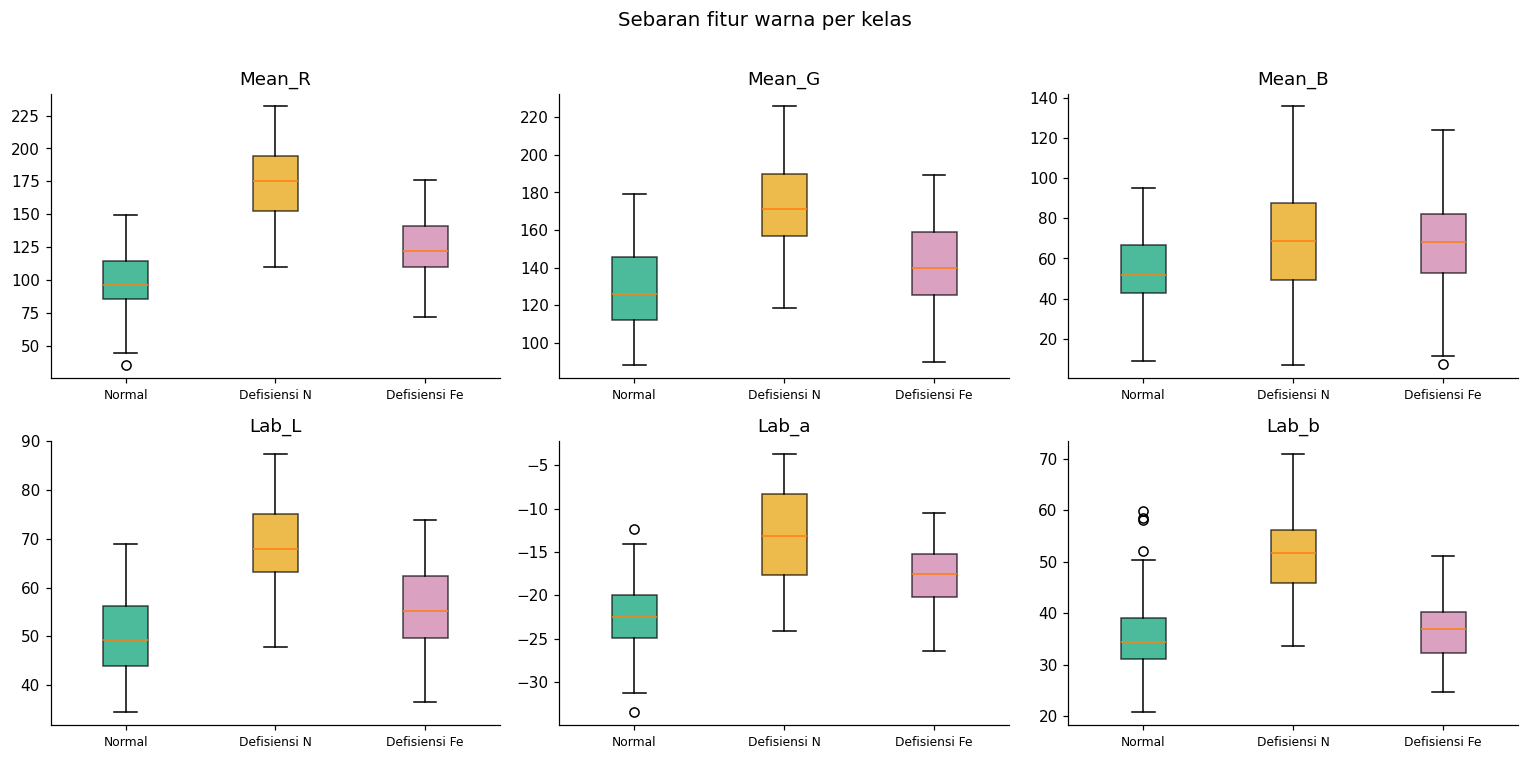

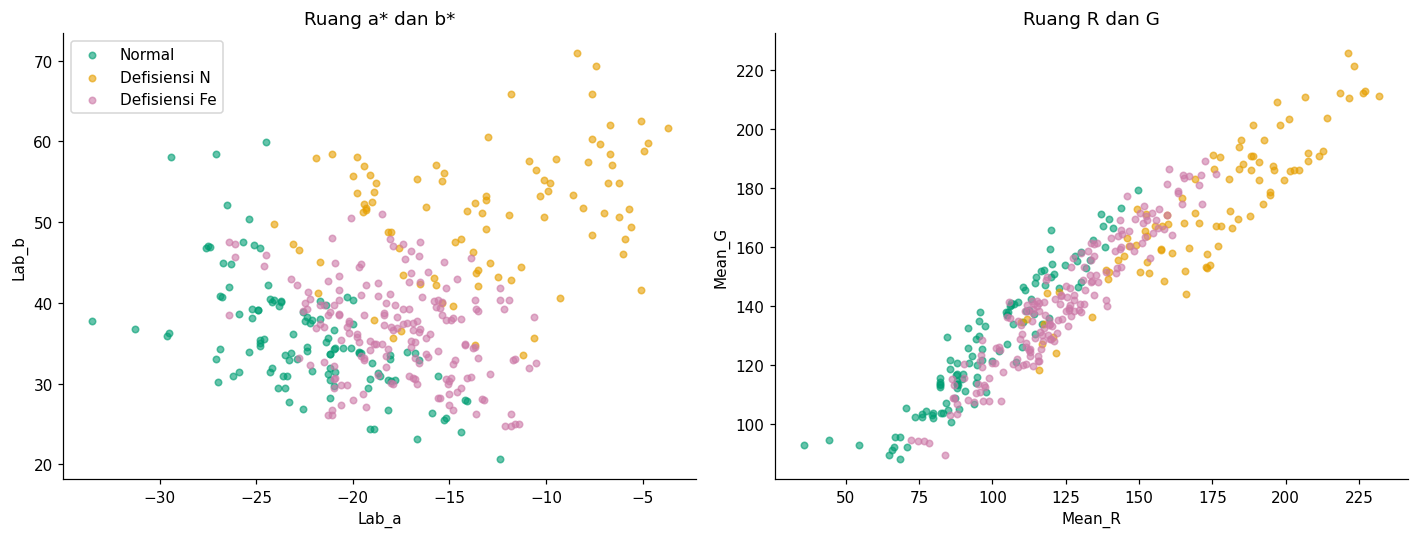

In [19]:
ok_features = features_df[(features_df["origin"] == "roboflow") & (features_df["qc_status"] == pp.QC_OK)]
feature_names = list(pp.FEATURES_A2)

describe = ok_features.groupby("label")[feature_names].agg(["mean", "std", "min", "max"]).round(1).reindex(CLASSES)
display(describe)
describe.to_csv(TABLES_DIR / "01_feature_summary_per_class.csv")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, name in zip(axes.ravel(), feature_names):
    box = ax.boxplot(
        [ok_features[ok_features["label"] == c][name].dropna() for c in CLASSES],
        patch_artist=True,
        tick_labels=[CLASS_LABEL_ID[c] for c in CLASSES],
    )
    for patch, c in zip(box["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLORS[c])
        patch.set_alpha(0.7)
    ax.set_title(name)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Sebaran fitur warna per kelas", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_figure(fig, "01_feature_boxplots.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for c in CLASSES:
    subset = ok_features[ok_features["label"] == c]
    axes[0].scatter(subset["Lab_a"], subset["Lab_b"], s=18, alpha=0.6, color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
    axes[1].scatter(subset["Mean_R"], subset["Mean_G"], s=18, alpha=0.6, color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
axes[0].set_xlabel("Lab_a")
axes[0].set_ylabel("Lab_b")
axes[0].set_title("Ruang a* dan b*")
axes[1].set_xlabel("Mean_R")
axes[1].set_ylabel("Mean_G")
axes[1].set_title("Ruang R dan G")
axes[0].legend()
fig.tight_layout()
save_figure(fig, "01_feature_scatter.png")
plt.show()

##### 7.6 Korelasi antar fitur

$$
\rho_{XY} = \frac{\sum_{i}(x_{i} - \bar{x})(y_{i} - \bar{y})}{\sqrt{\sum_{i}(x_{i} - \bar{x})^{2}}\ \sqrt{\sum_{i}(y_{i} - \bar{y})^{2}}}
$$

,Mean_R,Mean_G,Mean_B,Lab_L,Lab_a,Lab_b
Mean_R,1.00,0.94,0.61,0.96,0.60,0.62
Mean_G,0.94,1.00,0.71,1.00,0.31,0.54
Mean_B,0.61,0.71,1.00,0.70,0.22,-0.21
Lab_L,0.96,1.00,0.70,1.00,0.38,0.55
Lab_a,0.60,0.31,0.22,0.38,1.00,0.27
Lab_b,0.62,0.54,-0.21,0.55,0.27,1.00


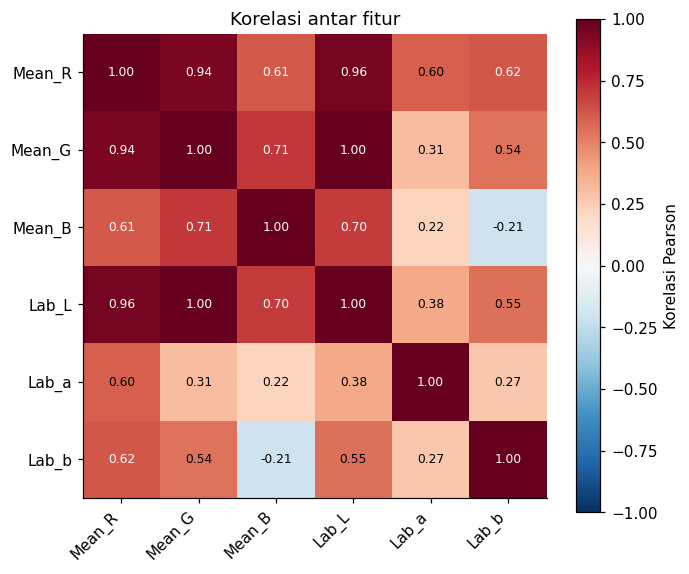

In [20]:
correlation = ok_features[feature_names].corr().round(2)
display(correlation)
correlation.to_csv(TABLES_DIR / "01_feature_correlation.csv")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
image = ax.imshow(correlation.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(feature_names)), feature_names, rotation=45, ha="right")
ax.set_yticks(range(len(feature_names)), feature_names)
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        value = correlation.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=ax, label="Korelasi Pearson")
ax.set_title("Korelasi antar fitur")
fig.tight_layout()
save_figure(fig, "01_feature_correlation.png")
plt.show()

#### 8. Foto Primer

$$
\text{persentil}(v) = \frac{\#\{x \in S_{normal} : x < v\}}{|S_{normal}|} \times 100
$$

dengan $v$ nilai fitur foto primer dan $S_{normal}$ himpunan nilai fitur yang sama pada foto Roboflow berkelas normal yang lolos QC.

Foto primer: 8 | lolos QC: 8


,image_id,qc_status,mask_area_ratio,Mean_R,Mean_G,Mean_B,Lab_L,Lab_a,Lab_b
0,primer1.jpeg,ok,0.4225,110.3,129.4,48.2,51.1,-19.2,40.1
1,primer2.jpeg,ok,0.4229,110.3,129.3,48.2,51.1,-19.2,40.1
2,primer3.jpeg,ok,0.4225,110.3,129.4,48.2,51.1,-19.2,40.1
3,primer4.jpeg,ok,0.4229,110.3,129.3,48.2,51.1,-19.2,40.1
4,primer5.jpeg,ok,0.4225,110.3,129.4,48.2,51.1,-19.2,40.1
5,primer6.jpeg,ok,0.4225,110.3,129.4,48.2,51.1,-19.2,40.1
6,primer7.jpeg,ok,0.4227,110.3,129.3,48.3,51.1,-19.2,40.1
7,primer8.jpeg,ok,0.4230,110.4,129.3,48.3,51.1,-19.2,40.1


,Mean_R,Mean_G,Mean_B,Lab_L,Lab_a,Lab_b
image_id,,,,,,
primer1.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer2.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer3.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer4.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer5.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer6.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer7.jpeg,67.0,53.0,43.0,55.0,78.0,78.0
primer8.jpeg,67.0,53.0,43.0,55.0,78.0,78.0


Nilai di luar persentil 5 sampai 95: 0 dari 48


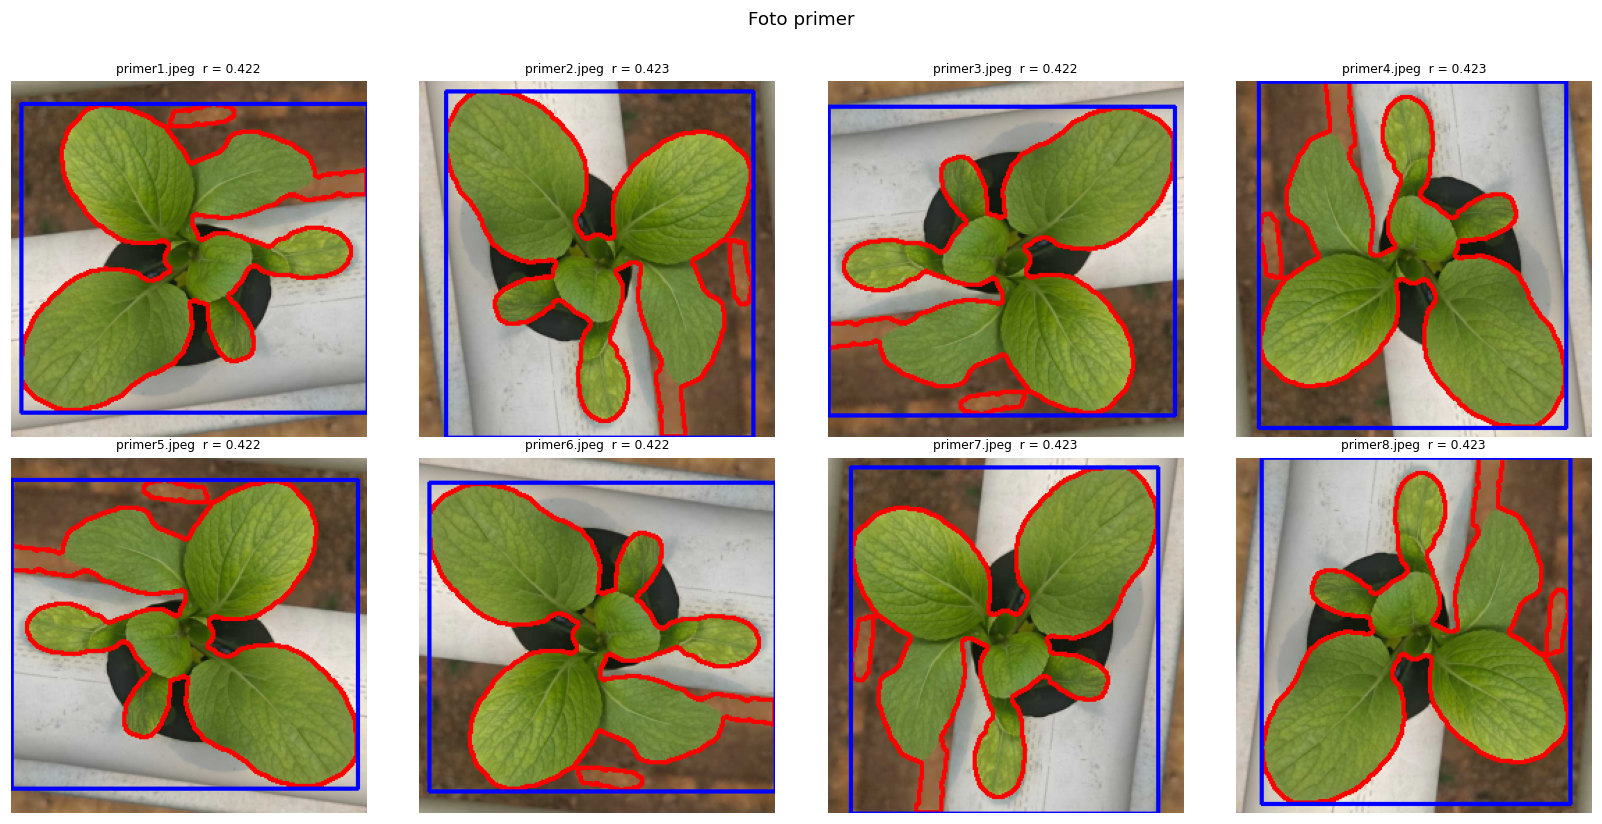

In [21]:
primary_features = features_df[features_df["origin"] == "primary"].copy()
reference = ok_features[ok_features["label"] == "normal"]
print("Foto primer:", len(primary_features), "| lolos QC:", int((primary_features["qc_status"] == pp.QC_OK).sum()))

if len(primary_features):
    display(primary_features[["image_id", "qc_status", "mask_area_ratio"] + feature_names].reset_index(drop=True))
    percentile_table = pd.DataFrame(
        {name: [(reference[name] < value).mean() * 100 for value in primary_features[name]] for name in feature_names},
        index=primary_features["image_id"],
    ).round(0)
    display(percentile_table)
    percentile_table.to_csv(TABLES_DIR / "01_primary_percentiles.csv")
    outside = (percentile_table < 5) | (percentile_table > 95)
    print(f"Nilai di luar persentil 5 sampai 95: {int(outside.values.sum())} dari {outside.size}")

    fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
    axes = axes.ravel()
    for ax in axes:
        ax.axis("off")
    for ax, row in zip(axes, primary_features.head(8).itertuples()):
        result = pp.process_image(pp.read_image_bgr(RAW_DIR / row.folder / row.image_id), config_final, keep_steps=True)
        ax.imshow(to_rgb(result.steps["overlay"]))
        ax.set_title(f"{row.image_id[:22]}  r = {row.mask_area_ratio:.3f}", fontsize=8)
    fig.suptitle("Foto primer", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    save_figure(fig, "01_primary_overlays.png")
    plt.show()

#### 9. Waktu Komputasi

$$
\bar{t} = \frac{1}{n}\sum_{i=1}^{n} t_{i}, \qquad
s = \sqrt{\frac{1}{n - 1}\sum_{i=1}^{n}\bigl(t_{i} - \bar{t}\bigr)^{2}}
$$

In [22]:
TIMING_IMAGES = 30
TIMING_REPEATS = 5
timing_frame = roboflow.sample(n=min(TIMING_IMAGES, len(roboflow)), random_state=SEED)

stage_names = ["baca berkas", "1 resize", "2 gaussian blur", "3 konversi CIELAB", "4 threshold Otsu",
               "5 morfologi", "6-7 masking + kontur", "8 ekstraksi warna"]
measurements = {name: [] for name in stage_names}
measurements["total (tanpa baca berkas)"] = []


def timed(function, *args):
    started = time.perf_counter()
    output = function(*args)
    return output, (time.perf_counter() - started) * 1000.0


for repeat in range(TIMING_REPEATS + 1):
    for row in timing_frame.itertuples():
        bgr, t_read = timed(pp.read_image_bgr, RAW_DIR / row.folder / row.image_id)
        resized, t_resize = timed(pp.resize_square, bgr, config_base.resize)
        blurred, t_blur = timed(pp.gaussian_blur, resized, config_base.blur_kernel)
        lab_blurred, t_lab = timed(pp.to_lab_uint8, blurred)
        (values, leaf_is_high), t_values = timed(pp.segmentation_values, lab_blurred, config_base.segmentation_channel)
        (raw_mask, _), t_otsu = timed(pp.threshold_mask, values, leaf_is_high)
        mask, t_morph = timed(pp.clean_mask, raw_mask, config_base.morphology_size, config_base.component_rule, config_base.min_component_ratio)

        started = time.perf_counter()
        pp.apply_mask(resized, mask)
        pp.find_leaf_contour(mask)
        t_mask = (time.perf_counter() - started) * 1000.0

        started = time.perf_counter()
        pp.extract_features(resized, pp.to_lab_uint8(resized), mask)
        t_features = (time.perf_counter() - started) * 1000.0

        if repeat == 0:
            continue
        stage_values = [t_read, t_resize, t_blur, t_lab, t_values + t_otsu, t_morph, t_mask, t_features]
        for name, value in zip(stage_names, stage_values):
            measurements[name].append(value)
        measurements["total (tanpa baca berkas)"].append(sum(stage_values) - t_read)

timing_table = pd.DataFrame(
    {
        name: {
            "rata-rata (ms)": np.mean(values),
            "simpangan baku (ms)": np.std(values, ddof=1),
            "median (ms)": np.median(values),
            "persentil 95 (ms)": np.percentile(values, 95),
        }
        for name, values in measurements.items()
    }
).T.round(3)
display(timing_table)
timing_table.to_csv(TABLES_DIR / "01_timing_per_stage.csv")

hardware = pd.Series(
    {
        "Sistem operasi": f"{platform.system()} {platform.release()}",
        "Prosesor (identifikasi sistem)": platform.processor() or "tidak tersedia",
        "Inti fisik / logis": f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count(logical=True)}",
        "RAM total (GB)": round(psutil.virtual_memory().total / 1024**3, 1),
        "Python": platform.python_version(),
        "OpenCV": cv2.__version__,
        "GPU dipakai": "tidak",
    },
    name="nilai",
)
display(hardware.to_frame())
hardware.to_frame().to_csv(TABLES_DIR / "01_hardware.csv")

total_ms = measurements["total (tanpa baca berkas)"]
print(f"Satu gambar: rata-rata {np.mean(total_ms):.1f} ms, persentil 95 {np.percentile(total_ms, 95):.1f} ms")
print(f"Enam lubang per bingkai: sekitar {6 * np.mean(total_ms):.0f} ms")

,rata-rata (ms),simpangan baku (ms),median (ms),persentil 95 (ms)
baca berkas,10.589,17.833,2.801,53.331
1 resize,3.858,6.154,1.051,20.332
2 gaussian blur,0.201,0.046,0.194,0.283
3 konversi CIELAB,0.343,0.081,0.324,0.514
4 threshold Otsu,0.455,0.164,0.403,0.822
5 morfologi,0.800,0.222,0.741,1.082
6-7 masking + kontur,0.503,0.172,0.446,0.846
8 ekstraksi warna,1.774,0.276,1.731,2.241
total (tanpa baca berkas),7.935,6.155,5.222,23.797


,nilai
Sistem operasi,Windows 10
Prosesor (identifikasi sistem),"Intel64 Family 6 Model 151 Stepping 2, Genuine..."
Inti fisik / logis,8 / 12
RAM total (GB),11.7
Python,3.10.6
OpenCV,4.10.0
GPU dipakai,tidak


Satu gambar: rata-rata 7.9 ms, persentil 95 23.8 ms
Enam lubang per bingkai: sekitar 48 ms


#### 10. Penyimpanan Hasil

In [23]:
output_columns = ["image_id", "source_group", "label", "origin", "qc_status", "mask_area_ratio",
                  "Mean_R", "Mean_G", "Mean_B", "Lab_L", "Lab_a", "Lab_b"]
features_out = features_df[output_columns].sort_values(["origin", "label", "image_id"]).reset_index(drop=True)
features_path = PROCESSED_DIR / "features.csv"
features_out.to_csv(features_path, index=False)

params = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "pipeline": config_final.to_dict(),
    "selection": {
        "segmentation_channel_setting": SEGMENTATION_CHANNEL,
        "channel_outlier_counts": outlier_counts,
        "channel_tie_margin_share": TIE_MARGIN,
        "channel_worst_class_share": {c: round(float(v), 4) for c, v in worst_share.items()},
        "component_rule": COMPONENT_RULE,
        "tukey_k": TUKEY_K,
    },
    "libraries": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "scikit_image": skimage.__version__,
        "pandas": pd.__version__,
    },
    "dataset": {
        "files": int(len(manifest)),
        "roboflow_files": int((manifest["origin"] == "roboflow").sum()),
        "primary_files": int((manifest["origin"] == "primary").sum()),
        "manifest_sha1": manifest_sha1,
    },
}
params_path = PROCESSED_DIR / "preprocessing_params.json"
params_path.write_text(json.dumps(params, indent=2), encoding="utf-8")
print("Disimpan:", features_path)
print("Disimpan:", params_path)

ok_rows = features_out[features_out["qc_status"] == pp.QC_OK]
checks = {
    "tidak ada nilai kosong pada fitur baris ok": not ok_rows[list(pp.FEATURES_A2)].isna().any().any(),
    "Mean_R/G/B dalam 0..255": bool(ok_rows[list(pp.FEATURES_A1)].apply(lambda c: c.between(0, 255)).all().all()),
    "Lab_L dalam 0..100": bool(ok_rows["Lab_L"].between(0, 100).all()),
    "jumlah baris sama dengan manifest": len(features_out) == len(manifest),
    "image_id unik per folder": not features_df.duplicated(["folder", "image_id"]).any(),
}
for name, passed in checks.items():
    print(("LULUS  " if passed else "GAGAL  ") + name)

Disimpan: D:\LARAGON\www\nutrify\ml\data\processed\features.csv
Disimpan: D:\LARAGON\www\nutrify\ml\data\processed\preprocessing_params.json
LULUS  tidak ada nilai kosong pada fitur baris ok
LULUS  Mean_R/G/B dalam 0..255
LULUS  Lab_L dalam 0..100
LULUS  jumlah baris sama dengan manifest
LULUS  image_id unik per folder


#### 11. Ringkasan

In [24]:
valid_groups = roboflow_features[roboflow_features["qc_status"] == pp.QC_OK].groupby("label")["source_group"].nunique()
final_summary = (
    roboflow_features.groupby("label")
    .agg(
        berkas=("image_id", "size"),
        lolos_qc=("qc_status", lambda s: int((s == pp.QC_OK).sum())),
        foto_sumber=("source_group", "nunique"),
    )
    .reindex(CLASSES)
)
final_summary["foto_sumber_lolos_qc"] = valid_groups.reindex(CLASSES).fillna(0).astype(int)
final_summary.loc["total"] = final_summary.sum()
display(final_summary)
final_summary.to_csv(TABLES_DIR / "01_final_summary.csv")

print("Kanal segmentasi :", config_final.segmentation_channel)
print("Aturan komponen  :", config_final.component_rule)
print("Batas luas daun  :", config_final.min_leaf_area_ratio, "sampai", config_final.max_leaf_area_ratio)
print("SHA-1 dataset    :", manifest_sha1)

,berkas,lolos_qc,foto_sumber,foto_sumber_lolos_qc
label,,,,
normal,112,112,72,72
n_deficiency,92,92,20,20
fe_deficiency,176,176,44,44
total,380,380,136,136


Kanal segmentasi : b
Aturan komponen  : relative
Batas luas daun  : 0.02 sampai 0.825
SHA-1 dataset    : ad8433fffe733d4da01783e1a7750799ebb33ac6
